In [39]:
data_path = "../data/out/parsed_data.txt"
with open(data_path, "r") as f:
    data = f.read()
data = eval(data)

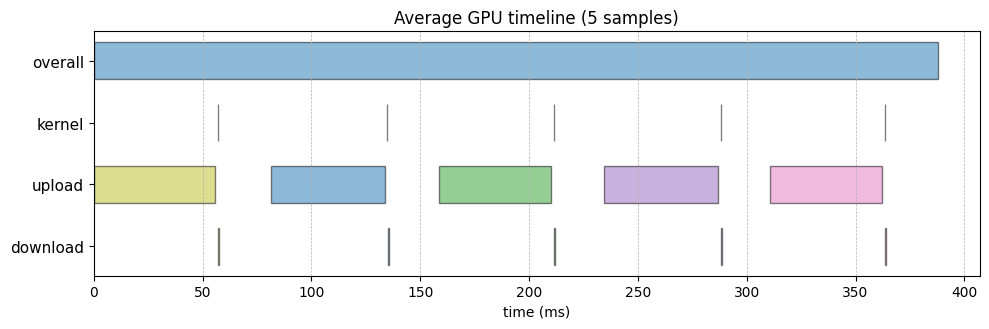

In [40]:
from __future__ import annotations
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple
import warnings

_NS_TO_MS = 1


def _stack_to_array(seqs: List[List[int]]) -> Tuple[np.ndarray, int]:
    """
    Safely stack nested lists with possibly unequal batch lengths.
    """
    lengths = [len(s) for s in seqs]
    nb = max(lengths)
    if len(set(lengths)) != 1:
        warnings.warn("Unequal batch counts across samples; padding with NaN.")
    arr = np.full((len(seqs), nb), np.nan, dtype=float)
    for i, s in enumerate(seqs):
        arr[i, : len(s)] = s
    return arr, nb


def _mean_per_batch(seqs: List[List[int]]) -> np.ndarray:
    arr, _ = _stack_to_array(seqs)
    return np.nanmean(arr, axis=0)


def _mean_and_shift_starts(start_seqs: List[List[int]]) -> np.ndarray:
    """
    Shift each sample so its first batch starts at 0, *then* average.
    """
    arr, _ = _stack_to_array(start_seqs)
    # subtract the first non-nan start in each sample
    offsets = np.nanmin(arr, axis=1, keepdims=True)
    shifted = arr - offsets
    return np.nanmean(shifted, axis=0)


def plot_gpu_timeline(data: Dict[str, List]) -> None:
    # ------------------------------------------------------------------
    # Identify keys programmatically so the script is robust to renames
    # ------------------------------------------------------------------
    overall_ms = np.mean(data["overall_time"]) * _NS_TO_MS

    # Per batch durations and starts
    durations_ms = {}
    starts_ms = {}
    zero_start = 0
    stage_keys = [k for k in data
                  if k.endswith("_time") and not k.endswith('overall_time')]
    for sk in stage_keys:
        if sk == "overall_time":
            continue
        stage = sk[:-5].lower()  # strip "_time"
        
        durations_ms[stage] = _mean_per_batch(data[sk]) * _NS_TO_MS
        
        start_arr_key = "Start_" + sk[0].lower() + sk[1:-5]
        if stage == "batch":
            start_arr_key = "Start_read"
        starts_ms[stage] = _mean_per_batch(
            np.array(data[start_arr_key])-zero_start) * _NS_TO_MS

    # ------------------------------------------------------------------
    # Plot -------------------------------------------------------------
    # ------------------------------------------------------------------
    stages_plot_order = ["download", "upload", "kernel", "batch", "overall"]
    # Filter out missing stages gracefully
    stages_plot_order = [s for s in stages_plot_order if s in durations_ms or s == "overall"]

    fig, ax = plt.subplots(figsize=(10, 1 + 0.6 * len(stages_plot_order)))
    barh_kwargs = dict(height=0.6, align="center", alpha=0.5, edgecolor="black")

    yticks = []
    yticklabels = []
    y_base = 0

    for stage in stages_plot_order:
        if stage == "overall":
            ax.barh(y=y_base,width=overall_ms,left=0,**barh_kwargs,label="overall",)
        else:
            for i, (left, width) in enumerate(list(zip(starts_ms[stage], durations_ms[stage]))):
                ax.barh(y=y_base, width=width, left=left, **barh_kwargs, color=f"C{i*2}")
        yticks.append(y_base)
        yticklabels.append(stage)
        y_base += 1

    ax.set_yticks(yticks)
    ax.set_yticklabels(yticklabels, fontsize=11)
    ax.set_xlabel("time (ms)")
    ax.set_title("Average GPU timeline ({} samples)".format(len(data["overall_time"])))
    ax.grid(axis="x", linestyle="--", linewidth=0.5)
    plt.tight_layout()
    plt.show()

plot_gpu_timeline(data)